# Empirical power analysis from pilot fNIRS data

We inject known responses into intact noise-only pilot recordings and run the proposed first-level pipeline. Each channel/chromophore gets its own sensitivity-versus-effect-size curve, preserving temporal and spatial noise structure rather than assuming spherical errors.

**Convention:** effect size is the absolute coefficient of the injected HRF regressor, in **micromolar** (not Cohen's d, a t statistic, or the older `simData.Data` SNR). HbO responses are positive and HbR responses negative. Detection is at **empirical per-channel false-positive rate (FPR) 0.05**, as determined by matched null simulations. FPR is not false-discovery rate (FDR); this example does **not** claim BH FDR control or use `q < 0.05`.

The notebook first calibrates per-channel first-level power, then demonstrates group sample-size estimation for one channel by simulating independent subjects and comparing IID with AR noise.

In [1]:
import copy
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

from pyBrainAnalyzIR.testing.simulations.simData import ARnoise
from pyBrainAnalyzIR.testing.power_analysis import (
    DEFAULT_EFFECT_SIZES, PowerCalibration, inject_activation, power_analysis,
)
from pyBrainAnalyzIR.testing.power_analysis.sample_size import (
    estimate_noise_scale_factors, fit_sample_size_subject,
    stimulus_template, theoretical_n80,
)
from pyBrainAnalyzIR.pipelines.default_pipelines import default_pipelines

# Thirty independent simulated recordings stand in for existing pilot data.
# No stimuli or activation are added here.
pilot_rng = np.random.default_rng(1801)
time = np.arange(0., 180., 0.25)  # three minutes at 4 Hz
pilot_data = [ARnoise(t=time, P=10, random_seed=pilot_rng) for _ in range(30)]

# Vary channel noise amplitude while retaining the AR/spatial noise structure.
# These illustrative levels put the power transition inside a compact effect grid.
for rec in pilot_data:
    rec['amp'] = rec['amp'].isel(channel=slice(None, None, 2))  # eight demo channels
channel_noise_scale = np.linspace(3., 12., pilot_data[0]['amp'].sizes['channel'])
for rec in pilot_data:
    intensity = rec['amp'].pint.magnitude
    intensity[:] = 100 * np.exp(np.log(intensity / 100) * channel_noise_scale[None, :, None])
print(f'{len(pilot_data)} noise-only pilots; {len(time)} samples each')
assert all(len(rec.stim) == 0 for rec in pilot_data)


30 noise-only pilots; 720 samples each


In [2]:
# Proposed study: one event type, 10 s ON / uniform [10, 20] s OFF.
stimulus = stimulus_template(time, random_seed=1802)
display(stimulus)
off_times = np.diff(stimulus.onset) - 10.
assert np.all((off_times >= 10.) & (off_times <= 20.))
# Cedalion calls stimulus amplitude 'value'; injection also accepts 'amp'.

,onset,duration,value,trial_type
0,15.000000,10.0,1.0,task
1,44.385318,10.0,1.0,task
2,69.075652,10.0,1.0,task
3,94.609883,10.0,1.0,task
4,120.202659,10.0,1.0,task
5,141.369996,10.0,1.0,task


In [3]:
# Default first-level pipeline: intensity -> OD -> MBLL -> 4 Hz -> AR-IRLS GLM.
pipeline = default_pipelines.first_level_analysis.pipeline()
pipeline.set_all_options({'verbose': False, 'max_jobs': 1})  # avoid nested GLM workers; parallelize independent fits below
pipeline.show()


Input Data:
Options:
	InputName : amp
Calculate Optical Density:
Options:
	<none>
Calculate Modified Beer-Lambert:
	Citation: Cope & Delpy:

Options:
	spectrum : prahl
	dpf      : [6, 6]
Resample:
Options:
	Fs : 4
GLM Model:
	Citation: Barker, Jeffrey W., Ardalan Aarabi, and Theodore J. Huppert. Autoregressive model based algorithm for correcting motion and serially correlated errors in fNIRS. Biomedical optics express 4.8 (2013): 1366-1379:

Options:
	noise_model                   : ar_irls
	ar_order                      : 30
	ar_estimator                  : robust
	max_jobs                      : 1
	basis_function                : gamma
	Add_Short_Seperations         : False
	Short_Seperation_Max_Distance : 1.5 centimeter
	drift_order                   : 0
	verbose                       : False


## Build the per-channel empirical calibration

Each iteration resamples one of the 30 pilots and generates a new jittered design. The identical noise/design pair is analyzed with zero activation and with each requested nonzero coefficient. Every channel receives the known HbO+/HbR- response; a matched all-null fit provides negative examples for each channel's ROC. Signal is injected in concentration space and projected back into raw intensity before running the entire pipeline. Injection and default analysis both use the same normalized gamma HRF and default MBLL convention (Prahl, DPF=6).

The default effect grid is `(0.2, 0.3, 0.4, 0.5, 0.6)` micromolar. The notebook tests an extended `(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 1.0, 1.5)` grid: 0.1 is included to avoid starting above the easiest channel's 80% crossing, while 1.5 tests whether even the noisiest channel reaches 80%. **500 iterations is still an exploratory calibration**: it supplies 25 null observations in the 5% tail. For stable thresholds, use more iterations and assess stability across seeds/pilot resamples. The four-thread joblib pool runs independent effect-size fits; BLAS/GLM nested parallelism is disabled to avoid oversubscription. Runtime is approximately `iterations * (1 + number_of_effects)` pipeline fits.

A callable stimulus template re-jitters designs each iteration. Pass the fixed `stimulus` DataFrame instead to condition on precisely that timing. Real pilot data must be noise-only/resting or appropriately residualized first: existing task-locked activation is not automatically removed.

In [4]:
effect_sizes = (0.1, *DEFAULT_EFFECT_SIZES, 1.0, 1.5)
num_iterations = 100
calibration = power_analysis(
    pilot_data, stimulus_template, pipeline,
    effect_sizes=effect_sizes, num_iterations=num_iterations,
    alpha=0.05, basis='gamma', random_seed=1803, verbose=False,
    n_jobs=4,  # joblib threading across independent effect-size fits
)
print(f'{len(calibration.records):,} scored channel/chromophore tests')
display(calibration.curve.head(12))


/var/folders/70/r3lyd5zs3bq124nb23rkgnjm0000gn/T/ipykernel_37419/1770837605.py:3: UserWarning: Few null-tail samples: use >= 10/alpha iterations for stable thresholds; this run is exploratory.
  calibration = power_analysis(


14,400 scored channel/chromophore tests


,Channel,Type,EffectSize,Sensitivity,Power,N,Threshold,NullFPR,NullCount
0,S1D1,HbO,0.1,0.19,0.19,100,0.015497,0.05,100
1,S1D1,HbO,0.2,0.45,0.45,100,0.015497,0.05,100
2,S1D1,HbO,0.3,0.84,0.84,100,0.015497,0.05,100
3,S1D1,HbO,0.4,1.00,1.00,100,0.015497,0.05,100
4,S1D1,HbO,0.5,1.00,1.00,100,0.015497,0.05,100
5,S1D1,HbO,0.6,1.00,1.00,100,0.015497,0.05,100
6,S1D1,HbO,1.0,1.00,1.00,100,0.015497,0.05,100
7,S1D1,HbO,1.5,1.00,1.00,100,0.015497,0.05,100
8,S1D1,HbR,0.1,0.53,0.53,100,0.062093,0.05,100
9,S1D1,HbR,0.2,0.94,0.94,100,0.062093,0.05,100


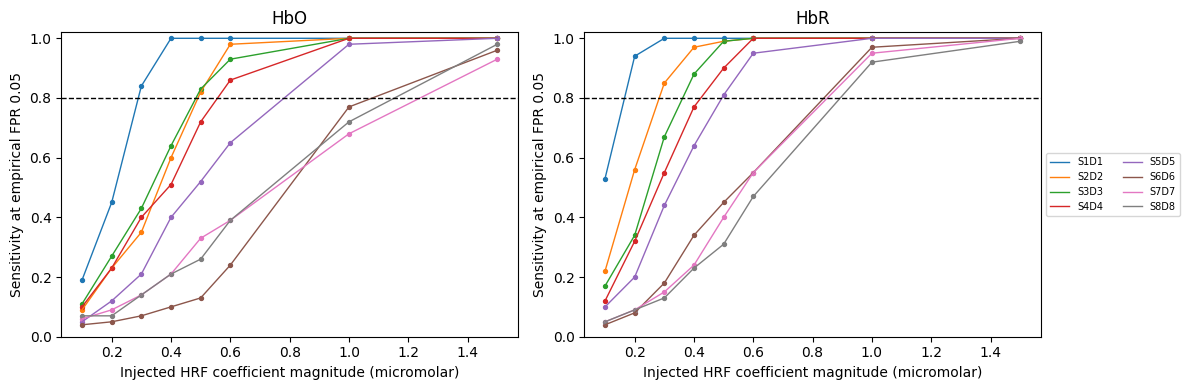

,Channel,Type,NullCount,Threshold,NullFPR
0,S1D1,HbO,100,0.015497,0.05
8,S1D1,HbR,100,0.062093,0.05
16,S2D2,HbO,100,0.002651,0.05
24,S2D2,HbR,100,0.018861,0.05
32,S3D3,HbO,100,0.039291,0.05
40,S3D3,HbR,100,0.021035,0.05
48,S4D4,HbO,100,0.054879,0.05
56,S4D4,HbR,100,0.039552,0.05
64,S5D5,HbO,100,0.022788,0.05
72,S5D5,HbR,100,0.029508,0.05


In [5]:
calibration.draw()
plt.show()

# Raw sensitivities are the dots; lines are isotonic (monotone) fits.
# NullFPR is an in-sample diagnostic at the strict null-derived threshold.
null_diagnostics = calibration.curve.drop_duplicates(['Channel', 'Type'])[
    ['Channel', 'Type', 'NullCount', 'Threshold', 'NullFPR']
]
display(null_diagnostics)
assert (null_diagnostics.NullFPR <= calibration.alpha + 1e-12).all()


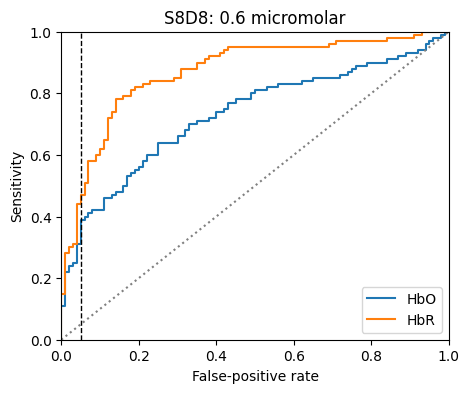

In [6]:
# ROC at one effect size for a representative channel (ties are grouped).
roc = calibration.roc_table()
example_channel = 'S8D8'  # high-noise channel with an unsaturated curve at 0.6 micromolar
fig, ax = plt.subplots(figsize=(5, 4))
for ty in ('HbO', 'HbR'):
    rows = roc[(roc.Channel == example_channel) & (roc.Type == ty)
               & (roc.EffectSize == 0.6)]
    ax.step(rows.FPR, rows.TPR, where='post', label=ty)
ax.plot([0, 1], [0, 1], ':', color='gray')
ax.axvline(0.05, ls='--', color='black', lw=1)
ax.set(xlabel='False-positive rate', ylabel='Sensitivity',
       title=f'{example_channel}: 0.6 micromolar', xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()


## An independent synthetic experiment and its effective power

Generate a new noise recording not used in calibration, inject a known response, and run exactly the same pipeline. We deliberately ignore the known truth when looking up the **measured** beta. This is a conditional, descriptive plug-in estimate: a noisy fitted beta is not the true effect, and post-hoc power is not evidence that a discovery is true. The additional lookup at the *known* injected coefficient helps illustrate the distinction.

In [7]:
experimental_noise = ARnoise(t=time, P=10, random_seed=1804)
experimental_noise['amp'] = experimental_noise['amp'].isel(channel=slice(None, None, 2))
intensity = experimental_noise['amp'].pint.magnitude
intensity[:] = 100 * np.exp(np.log(intensity / 100) * channel_noise_scale[None, :, None])
true_coefficient = 0.45  # HbO +0.45 / HbR -0.45 micromolar
experimental_data = inject_activation(
    experimental_noise, stimulus_template, true_coefficient,
    basis='gamma', random_seed=1805,
)
experimental_stats = copy.deepcopy(pipeline).run(experimental_data)['stats']
power_report = calibration.estimate_power(experimental_stats, target_power=0.8)
display(power_report)
display(calibration.power(true_coefficient).rename(columns={'Power': 'PowerAtKnownTruth'}))


,Channel,Type,Beta,P,EffectSize,Power,PowerStatus,MDC,MDCStatus,TargetPower,Alpha,Units
0,S1D1,HbO,0.393539,3.533661e-04,0.393539,0.989662,ok,0.289744,interpolated,0.8,0.05,micromolar
1,S1D1,HbR,-0.401431,6.170820e-11,0.401431,1.000000,ok,0.165854,interpolated,0.8,0.05,micromolar
2,S2D2,HbO,0.346850,2.289611e-05,0.346850,0.467124,ok,0.490909,interpolated,0.8,0.05,micromolar
3,S2D2,HbR,-0.488735,2.515160e-12,0.488735,0.987747,ok,0.282759,interpolated,0.8,0.05,micromolar
4,S3D3,HbO,0.285775,4.435464e-02,0.285775,0.407241,ok,0.484211,interpolated,0.8,0.05,micromolar
5,S3D3,HbR,-0.428625,2.972254e-04,0.428625,0.911487,ok,0.361905,interpolated,0.8,0.05,micromolar
6,S4D4,HbO,0.454038,2.429254e-04,0.454038,0.623479,ok,0.557143,interpolated,0.8,0.05,micromolar
7,S4D4,HbR,-0.541785,1.224963e-09,0.541785,0.941785,ok,0.423077,interpolated,0.8,0.05,micromolar
8,S5D5,HbO,0.531646,6.956311e-02,0.531646,0.561140,ok,0.781818,interpolated,0.8,0.05,micromolar
9,S5D5,HbR,-0.536773,1.032963e-03,0.536773,0.861482,ok,0.494118,interpolated,0.8,0.05,micromolar


,Channel,Type,EffectSize,PowerAtKnownTruth,InRange
0,S1D1,HbO,0.45,1.000,True
1,S1D1,HbR,0.45,1.000,True
2,S2D2,HbO,0.45,0.710,True
3,S2D2,HbR,0.45,0.980,True
4,S3D3,HbO,0.45,0.735,True
5,S3D3,HbR,0.45,0.935,True
6,S4D4,HbO,0.45,0.615,True
7,S4D4,HbR,0.45,0.835,True
8,S5D5,HbO,0.45,0.460,True
9,S5D5,HbR,0.45,0.725,True


,Channel,Type,MDC,MDCStatus,TargetPower,Alpha,Units
0,S1D1,HbO,0.289744,interpolated,0.8,0.05,micromolar
1,S1D1,HbR,0.165854,interpolated,0.8,0.05,micromolar
2,S2D2,HbO,0.490909,interpolated,0.8,0.05,micromolar
3,S2D2,HbR,0.282759,interpolated,0.8,0.05,micromolar
4,S3D3,HbO,0.484211,interpolated,0.8,0.05,micromolar
5,S3D3,HbR,0.361905,interpolated,0.8,0.05,micromolar
6,S4D4,HbO,0.557143,interpolated,0.8,0.05,micromolar
7,S4D4,HbR,0.423077,interpolated,0.8,0.05,micromolar
8,S5D5,HbO,0.781818,interpolated,0.8,0.05,micromolar
9,S5D5,HbR,0.494118,interpolated,0.8,0.05,micromolar


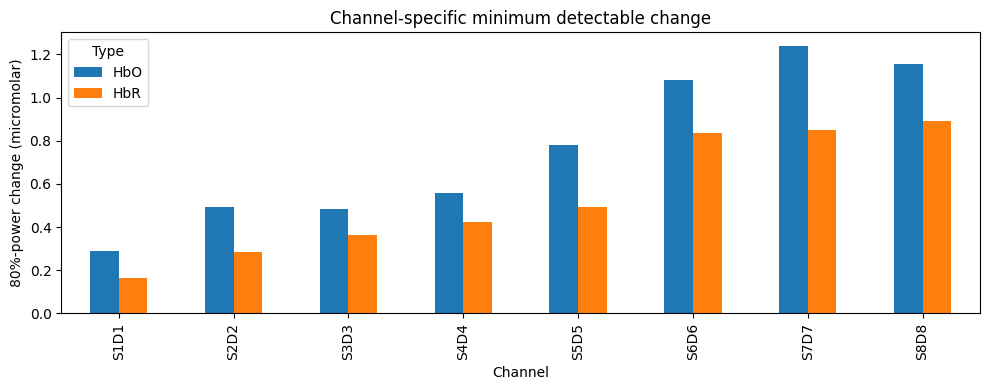

In [8]:
# Minimum detectable/discoverable change at 80% power, empirical FPR alpha=0.05.
mdc = calibration.minimum_detectable_change(power=0.8)
assert (mdc.MDCStatus == 'interpolated').all(), 'Effect grid does not bracket 80% power for every channel/type.'
display(mdc)
fig, ax = plt.subplots(figsize=(10, 4))
mdc.pivot(index='Channel', columns='Type', values='MDC').plot.bar(ax=ax)
ax.set(ylabel='80%-power change (micromolar)', title='Channel-specific minimum detectable change')
fig.tight_layout()
plt.show()


## Save, reload and extend the first-level calibration

Run the first calibration with 100 iterations, inspect the curve and plot, then enable `save_checkpoint` to persist it. To add iterations in the same kernel, set `additional_iterations` in the continuation cell. To continue in a later kernel, rerun the setup cells that recreate `pilot_data` and `pipeline`, skip the expensive initial calibration cell, set `load_checkpoint=True`, and set the additional iteration count. The saved RNG state continues the original random stream, and the checkpoint is updated after each extension. For example, 100 initial iterations plus 900 additional iterations gives 1,000 total.

Continuation requires the same pilot data, stimulus generator, pipeline, basis, alpha and effect-size grid. Do not pass a new `random_seed`; the checkpoint resumes its saved generator state. Only load pickle files you trust.

A calibration pickle created before resumable support can still be inspected, but it lacks the saved RNG and input signatures needed for safe continuation. Rerun and save the initial batch with this version before extending it.

In [ ]:
calibration_path = Path('first_level_power_calibration.pkl')
save_checkpoint = False
if save_checkpoint:
    with calibration_path.open('wb') as stream:
        pickle.dump(calibration, stream)
    print(f'Saved {calibration.records.Iteration.nunique()} iterations to '
          f'{calibration_path.resolve()}')

In [ ]:
load_checkpoint = False
if load_checkpoint:
    with calibration_path.open('rb') as stream:
        calibration = pickle.load(stream)
    if not isinstance(calibration, PowerCalibration):
        raise TypeError(f'{calibration_path} does not contain a PowerCalibration.')
    print(f'Loaded {calibration.records.Iteration.nunique()} iterations')
    display(calibration.curve.head(12))
    calibration.draw()
    plt.show()

additional_iterations = 0  # e.g. 900 to extend a saved 100-iteration calibration to 1,000
if additional_iterations:
    calibration = power_analysis(
        pilot_data, stimulus_template, pipeline,
        effect_sizes=calibration.effect_sizes,
        num_iterations=additional_iterations,
        initial_calibration=calibration,
        alpha=calibration.alpha, basis=calibration.basis,
        verbose=False, n_jobs=4,
    )
    with calibration_path.open('wb') as stream:
        pickle.dump(calibration, stream)
    print(f'Checkpoint now contains {calibration.records.Iteration.nunique()} iterations')
    display(calibration.curve.head(12))
    calibration.draw()
    plt.show()

## Sample-size calibration: IID versus AR noise

This one-channel demonstration simulates independent participants for a fixed single-condition task, runs each recording through the **same default AR-IRLS first-level pipeline** used above, then tests the participant HbO coefficients with a two-sided fixed-effects one-sample t-test (alpha 0.05). As requested, this is the no-random-effects analysis, not the toolkit's `MixedEffects` module.

The simulator is the only source of the noise-condition difference: `ARnoise(P=0)` gives temporally IID innovations and `ARnoise(P=10)` gives AR noise. A fixed per-wavelength scale, estimated from separate noise-only simulations, matches their pooled log-intensity SD so the comparison focuses on temporal dependence. Effects are in micromolar HRF-coefficient units. The normal-theory sample size uses the IID null-coefficient SD and the exact noncentral-t power for a two-sided one-sample test.

In [9]:
from joblib import Parallel, delayed
from scipy.stats import ttest_1samp
from pyBrainAnalyzIR.testing.simulations.simData import defaultProbe2D

# Use one measurement channel and the already-defined, fixed stimulus design.
group_geo, group_meas_list = defaultProbe2D()
group_meas_list = dict(group_meas_list)
group_meas_list['channel'] = group_meas_list['channel'].isel(channel=slice(0, 1))
group_channel = str(group_meas_list['channel'].values[0])

noise_orders = (0, 10)
noise_labels = {0: 'IID (P=0)', 10: 'AR (P=10)'}
noise_scale_factors = estimate_noise_scale_factors(
    group_geo, group_meas_list, time, noise_orders=noise_orders,
    target_log_intensity_sd=0.06, num_calibration=30, random_seed=1805,
)
sample_size_effects = (0.01, 0.02)
sample_sizes = (4, 5, 6, 7, 8, 9, 10, 11, 12, 16, 24, 32, 48)
sample_size_iterations = 20
sample_size_alpha = 0.05
sample_size_n_jobs = 4
print(f'One channel: {group_channel}; noise scale factors: {noise_scale_factors}')

One channel: S1D1; noise scale factors: {0: array([11.95207915, 11.99115281]), 10: array([0.57983058, 0.51066938])}


### Run the participant-level simulations

Each simulated participant contributes one noise-only first-level HbO fit. The injected signal is exactly the modeled HRF regressor, so adding an effect shifts that fitted coefficient by exactly the effect while leaving the GLM residuals and AR-IRLS weights unchanged. The effect-specific group coefficients are therefore computed by this exact shift rather than repeating an equivalent fit for every effect. Sample sizes use nested prefixes of each independently simulated participant set.

In [10]:
sample_size_rng = np.random.default_rng(1806)
sample_size_rejections = []
iid_null_coefficients = []

for noise_order in noise_orders:
    for iteration in range(sample_size_iterations):
        subject_seeds = sample_size_rng.integers(
            0, np.iinfo(np.uint32).max, size=max(sample_sizes), dtype=np.uint32
        )
        beta_matrix = np.asarray(Parallel(
            n_jobs=sample_size_n_jobs, backend='threading'
        )(
            delayed(fit_sample_size_subject)(
                noise_order, int(seed), geo2d=group_geo,
                meas_list=group_meas_list, times=time,
                noise_scale_factors=noise_scale_factors,
                stimulus=stimulus, pipeline=pipeline,
                effect_sizes=sample_size_effects,
            )
            for seed in subject_seeds
        ))
        null_coefficients = beta_matrix[:, 0] - sample_size_effects[0]
        if noise_order == 0:
            iid_null_coefficients.extend(null_coefficients.tolist())

        for effect_index, effect in enumerate(sample_size_effects):
            for n_subjects in sample_sizes:
                test = ttest_1samp(
                    beta_matrix[:n_subjects, effect_index],
                    popmean=0., alternative='two-sided',
                )
                sample_size_rejections.append({
                    'Noise': noise_labels[noise_order],
                    'Effect (uM)': effect,
                    'N': n_subjects,
                    'Iteration': iteration,
                    'Reject': bool(test.pvalue < sample_size_alpha),
                })
        if (iteration + 1) % 5 == 0:
            print(f'{noise_labels[noise_order]}: {iteration + 1}/'
                  f'{sample_size_iterations} iterations')

sample_size_power = (
    pd.DataFrame(sample_size_rejections)
    .groupby(['Noise', 'Effect (uM)', 'N'], as_index=False)
    .agg(Power=('Reject', 'mean'), Rejections=('Reject', 'sum'),
         Iterations=('Reject', 'size'))
)
iid_null_sd = float(np.std(iid_null_coefficients, ddof=1))
print(f'IID null subject-beta SD: {iid_null_sd:.5f} uM')
display(sample_size_power)

IID (P=0): 5/20 iterations
IID (P=0): 10/20 iterations
IID (P=0): 15/20 iterations
IID (P=0): 20/20 iterations
AR (P=10): 5/20 iterations


/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:128: RuntimeWarning: Bisquare regression reached 500 iterations before coefficient convergence.
  coefficients = _robust_fit(


AR (P=10): 10/20 iterations
AR (P=10): 15/20 iterations
AR (P=10): 20/20 iterations
IID null subject-beta SD: 0.00902 uM


,Noise,Effect (uM),N,Power,Rejections,Iterations
0,AR (P=10),0.01,4,0.10,2,20
1,AR (P=10),0.01,5,0.20,4,20
2,AR (P=10),0.01,6,0.10,2,20
3,AR (P=10),0.01,7,0.25,5,20
4,AR (P=10),0.01,8,0.30,6,20
5,AR (P=10),0.01,9,0.35,7,20
6,AR (P=10),0.01,10,0.50,10,20
7,AR (P=10),0.01,11,0.60,12,20
8,AR (P=10),0.01,12,0.60,12,20
9,AR (P=10),0.01,16,0.75,15,20


### Empirical and normal-theory minimum sample sizes

For the IID benchmark, the theoretical calculation assumes independent, normally distributed participant coefficients with the observed IID null SD and a two-sided one-sample t-test. The AR empirical estimate uses the same test and first-level pipeline, but the IID-derived theoretical N is retained as the comparison reference. Empirical N80 is the smallest tested N with at least 80% rejection frequency; if none qualifies, the table reports that it exceeds the tested range. With 20 iterations, each power estimate changes in increments of 0.05.

,Noise,Effect (uM),IID normal-theory N80,IID empirical power at theory N,Empirical N80 (tested grid)
0,IID (P=0),0.01,9,0.8,9
1,AR (P=10),0.01,9,0.8,24
2,IID (P=0),0.02,4,0.8,4
3,AR (P=10),0.02,4,0.8,8


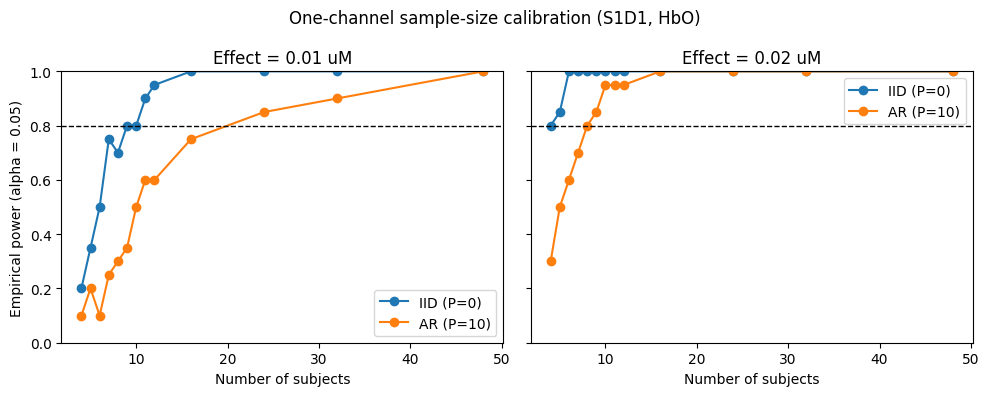

In [11]:
sample_size_summary = []
for effect in sample_size_effects:
    theory_n = theoretical_n80(effect, iid_null_sd, sample_size_alpha)
    iid_curve = sample_size_power[
        (sample_size_power['Noise'] == noise_labels[0])
        & (sample_size_power['Effect (uM)'] == effect)
    ].sort_values('N')
    iid_power_at_theory_n = float(np.interp(
        theory_n, iid_curve['N'], iid_curve['Power']
    ))
    for noise_order in noise_orders:
        curve = sample_size_power[
            (sample_size_power['Noise'] == noise_labels[noise_order])
            & (sample_size_power['Effect (uM)'] == effect)
        ]
        qualifying = curve.loc[curve['Power'] >= 0.80, 'N']
        empirical_n = (
            int(qualifying.min()) if not qualifying.empty
            else f">{max(sample_sizes)}"
        )
        sample_size_summary.append({
            'Noise': noise_labels[noise_order],
            'Effect (uM)': effect,
            'IID normal-theory N80': theory_n,
            'IID empirical power at theory N': iid_power_at_theory_n,
            'Empirical N80 (tested grid)': empirical_n,
        })

sample_size_summary = pd.DataFrame(sample_size_summary)
display(sample_size_summary)

fig, axes = plt.subplots(1, len(sample_size_effects), figsize=(10, 4), sharey=True)
for ax, effect in zip(np.atleast_1d(axes), sample_size_effects):
    subset = sample_size_power[sample_size_power['Effect (uM)'] == effect]
    for label in noise_labels.values():
        curve = subset[subset['Noise'] == label]
        ax.plot(curve['N'], curve['Power'], marker='o', label=label)
    ax.axhline(0.80, color='black', linestyle='--', linewidth=1)
    ax.set(title=f'Effect = {effect:g} uM', xlabel='Number of subjects',
           ylim=(0, 1))
    ax.legend()
axes[0].set_ylabel('Empirical power (alpha = 0.05)')
fig.suptitle(f'One-channel sample-size calibration ({group_channel}, HbO)')
fig.tight_layout()
plt.show()

## Reading and reusing the result

- `calibration.records` retains all simulation results; `curve` retains raw sensitivities, monotone fits, counts, and null thresholds. Labels, not row order, align measured results with calibration channels.
- `MDCStatus == 'interpolated'` means the grid brackets 80% power. `'above_range'` means 80% was not attained (MDC is NaN); extend the grid. `'at_or_below_range'` means the smallest tested effect already attains 80%: the reported grid boundary is an upper bound, not a precisely identified minimum; add smaller effects.
- `PowerStatus` reports measured coefficients outside the calibrated range or opposite to the simulated HbO+/HbR- direction. These lookups return NaN, not fabricated extrapolations.
- FPR thresholds are calibrated **in-sample** on null simulations. Their error control should be validated using independent null recordings/simulations before substantive use. No FDR control or independent-null validation is claimed here.
- Resampling and re-jittering preserve the finite pilots' non-spherical noise but do not manufacture independent participants. More iterations reduce Monte Carlo error, not uncertainty from having only 30 pilots. Existing task signals, nonstationarity, pipeline spatial/global processing, or different HRF/MBLL conventions can change the calibration. The all-channel activation pattern is part of this demo's assumptions.
- Reuse only with the same pipeline, coefficient units/normalization, montage, timing distribution and noise population. `pipeline_options`, `basis`, `alpha`, `condition`, and `pilot_count` are retained as metadata. Measured Statistics betas are assumed to be micromolar, as in the default pipeline.
- The sample-size demo below is separate from the first-level calibration: it simulates independent participants, fits the unchanged AR-IRLS first-level pipeline, and tests participant HbO coefficients with a fixed-effects one-sample t-test. Its IID normal-theory benchmark uses the simulated IID coefficient SD; its AR condition changes only the simulator noise order. This compact demonstration has no random effects and is not a general group-level calibration API. First-level curves cannot be scaled into sample-size estimates by a square-root rule.

The checkpoint cells above save, reload, and extend a calibration. Pickles can execute code when loaded; only load files you trust.